# Speeding up A2C Training with Vector Envs

This tutorial demonstrates training with vector environments to it speed up.


## Notice

If you encounter an RuntimeError like the following comment raised on multiprocessing/spawn.py, wrap up the code from `gym.make_vec=` or `gym.vector.AsyncVectorEnv` to the end of the code by `if__name__ == '__main__'`.

`An attempt has been made to start a new process before the current process has finished its bootstrapping phase.`


---


## Introduction

In this tutorial, you'll learn how to use vectorized environments to train an Advantage Actor-Critic agent.
We are going to use A2C, which is the synchronous version of the A3C algorithm [1].

Vectorized environments [3] can help to achieve quicker and more robust training by allowing multiple instances
of the same environment to run in parallel (on multiple CPUs). This can significantly reduce the variance and thus speeds up the training.

We will implement an Advantage Actor-Critic from scratch to look at how you can feed batched states into your networks to get a vector of actions
(one action per environment) and calculate the losses for actor and critic on minibatches of transitions.
Each minibatch contains the transitions of one sampling phase: `n_steps_per_update` steps are executed in `n_envs` environments in parallel
(multiply the two to get the number of transitions in a minibatch). After each sampling phase, the losses are calculated and one gradient step is executed.
To calculate the advantages, we are going to use the Generalized Advantage Estimation (GAE) method [2], which balances the tradeoff
between variance and bias of the advantage estimates.

The A2C agent class is initialized with the number of features of the input state, the number of actions the agent can take,
the learning rates and the number of environments that run in parallel to collect experiences. The actor and critic networks are defined
and their respective optimizers are initialized. The forward pass of the networks takes in a batched vector of states and returns a tensor of state values
and a tensor of action logits. The select_action method returns a tuple of the chosen actions, the log-probs of those actions, and the state values for each action.
In addition, it also returns the entropy of the policy distribution, which is subtracted from the loss later (with a weighting factor `ent_coef`) to encourage exploration.

The get_losses function calculates the losses for the actor and critic networks (using GAE), which are then updated using the update_parameters function.


---


In [1]:
# Author: Till Zemann
# License: MIT License

from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch import optim
from tqdm import tqdm

import gymnasium as gym
import pickle as pkl
print(torch.__version__)
from net.a2c import A2C, ContinuousA2C


1.12.0


## Advantage Actor-Critic (A2C)

The Actor-Critic combines elements of value-based and policy-based methods. In A2C, the agent has two separate neural networks:
a critic network that estimates the state-value function, and an actor network that outputs logits for a categorical probability distribution over all actions.
The critic network is trained to minimize the mean squared error between the predicted state values and the actual returns received by the agent
(this is equivalent to minimizing the squared advantages, because the advantage of an action is as the difference between the return and the state-value: A(s,a) = Q(s,a) - V(s).
The actor network is trained to maximize the expected return by selecting actions that have high expected values according to the critic network.

The focus of this tutorial will not be on the details of A2C itself. Instead, the tutorial will focus on how to use vectorized environments
and domain randomization to accelerate the training process for A2C (and other reinforcement learning algorithms).


In [2]:
def train(configuration, n_updates, actor_lr, critic_lr, simple_type, ei_type):
    # environment hyperparams
    n_seed = 5
    n_envs = 100
    n_steps_per_update = 128
    randomize_domain = False

    # agent hyperparams
    gamma = 0.99
    lam = 0.95  # hyperparameter for GAE
    ent_coef = 0.01  # coefficient for the entropy bonus (to encourage exploration)

    hidden_size = 64

    env_name = "HalfCheetah-v5"
    # configuration = 'eisep_actor'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # actor_lr = 0.001
    # critic_lr = 0.005
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic

    envs = gym.make_vec(env_name, num_envs=n_envs)
    obs_shape = envs.single_observation_space.shape[0]
    action_shape = envs.single_action_space.shape[0]
    # set the device
    use_cuda = True
    if use_cuda:
        device = torch.device("cuda")
    else:
        device = torch.device("cpu")


    # torch.autograd.set_detect_anomaly(True)
    torch.manual_seed(42)
    np.random.seed(42)
    critic_losses = np.zeros((n_seed, n_updates))
    actor_losses = np.zeros((n_seed, n_updates))
    entropies = np.zeros((n_seed, n_updates))
    returns = np.zeros((n_seed, n_updates))
    net_state_dicts = [None] * n_seed

    prefix = configuration
    # use tqdm to get a progress bar for training
    for seed in range(n_seed):
        torch.manual_seed(seed)
        np.random.seed(seed)
        # init the agent
        agent = ContinuousA2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration,
                              simple_type, ei_type)
        # create a wrapper environment to save episode returns and episode lengths

        envs = gym.make_vec(env_name, num_envs=n_envs)
        envs_wrapper = gym.wrappers.vector.RecordEpisodeStatistics(
            envs, buffer_length=n_envs * n_updates
        )
        agent.train()

        for sample_phase in tqdm(range(n_updates)):
            # we don't have to reset the envs, they just continue playing
            # until the episode is over and then reset automatically

            # reset lists that collect experiences of an episode (sample phase)
            ep_value_preds = torch.zeros(n_steps_per_update+1, n_envs, device=device)
            ep_rewards = torch.zeros(n_steps_per_update, n_envs, device=device)
            ep_action_log_probs = torch.zeros(n_steps_per_update, n_envs, device=device)
            ep_entropy = torch.zeros(n_steps_per_update, n_envs, device=device)
            masks = torch.zeros(n_steps_per_update, n_envs, device=device)

            # at the start of training reset all envs to get an initial state
            if sample_phase == 0:
                states, info = envs_wrapper.reset(seed=seed)
                hidden = agent.init_hidden(batch_size=n_envs)

            # play n steps in our parallel environments to collect data
            hidden = agent.detach_hidden(hidden)
            for step in range(n_steps_per_update):
                # select an action A_{t} using S_{t} as input for the agent
                actions, action_log_probs, state_value_preds, entropy, new_hidden = agent.select_action(
                    states, hidden
                )

                # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
                states, rewards, terminated, truncated, infos = envs_wrapper.step(
                    actions.detach().cpu().numpy()
                )

                ep_value_preds[step] = torch.squeeze(state_value_preds)
                ep_rewards[step] = torch.tensor(rewards, device=device)
                ep_action_log_probs[step] = action_log_probs
                ep_entropy[step] = entropy

                # add a mask (for the return calculation later);
                # for each env the mask is 1 if the episode is ongoing and 0 if it is terminated (not by truncation!)
                # masks[step] = torch.tensor([not term for term in terminated])
                done = np.logical_or(terminated, truncated)
                masks[step] = torch.tensor(~done, device=device, dtype=torch.float32)

                # reset hidden state for terminated environments
                hidden = agent.reset_hidden_on_done(new_hidden, done)

            with torch.no_grad():
                last_v, _, _ = agent.forward(states, hidden)
                # print(last_v.shape)
            ep_value_preds[-1] = last_v.squeeze(-1)  # shape: [n_envs]

            # calculate the losses for actor and critic
            critic_loss, actor_loss = agent.get_losses(
                ep_rewards,
                ep_action_log_probs,
                ep_value_preds,
                ep_entropy,
                masks,
                gamma,
                lam,
                ent_coef,
                device,
            )
            # update the actor and critic networks
            agent.update_parameters(critic_loss, actor_loss)

            # log the losses and entropy
            # critic_losses.append(critic_loss.detach().cpu().numpy())
            # actor_losses.append(actor_loss.detach().cpu().numpy())
            # entropies.append(entropy.detach().mean().cpu().numpy())
            critic_losses[seed, sample_phase] = critic_loss.detach().cpu().numpy()
            actor_losses[seed, sample_phase] = actor_loss.detach().cpu().numpy()
            entropies[seed, sample_phase] = ep_entropy.detach().mean().cpu().numpy()
            returns[seed, sample_phase] = ep_rewards.mean().cpu().numpy()
        net_state_dicts[seed] = agent.state_dict()
    info = {
        'critic_loss': critic_losses,
        'actor_loss': actor_losses,
        'entropy': entropies,
        'net_state_dict': net_state_dicts,
        'rewards': returns,
    }
    lrname=f'critic_{critic_lr}_actor_{actor_lr}'
    info_path = f'./rl/result/halfcheetah/simple_{simple_type}_ei_{ei_type}/{lrname}/{prefix}.pkl'
    os.makedirs(os.path.dirname(info_path), exist_ok=True)
    with open(info_path, 'wb') as f:
        pkl.dump(info, f)
    return info

In [3]:
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005]

simple_type = 'lstm'
ei_type = 'eisep'
for actor_lr in actor_lrs:
    for critic_lr in critic_lrs:
        for config in configurations:
            print(f"Training configuration: {config}, actor_lr: {actor_lr}, critic_lr: {critic_lr}")
            train(configuration=config, n_updates=1000, actor_lr=actor_lr, critic_lr=critic_lr,
                  simple_type=simple_type, ei_type=ei_type)

Training configuration: simple, actor_lr: 0.0003, critic_lr: 0.0015
Using <class 'net.rnncell_variant.SimpleLSTMCell'> RNN for actor and critic


100%|██████████| 1000/1000 [22:28<00:00,  1.35s/it]


Using <class 'net.rnncell_variant.SimpleLSTMCell'> RNN for actor and critic


100%|██████████| 1000/1000 [22:41<00:00,  1.36s/it]


Using <class 'net.rnncell_variant.SimpleLSTMCell'> RNN for actor and critic


100%|██████████| 1000/1000 [23:26<00:00,  1.41s/it]


... (230 outputs left out)

Using <class 'net.rnncell_variant.EILSTMCell'> for actor and critic


100%|██████████| 1000/1000 [17:36<00:00,  1.06s/it]


Using <class 'net.rnncell_variant.EILSTMCell'> for actor and critic


100%|██████████| 1000/1000 [17:50<00:00,  1.07s/it]


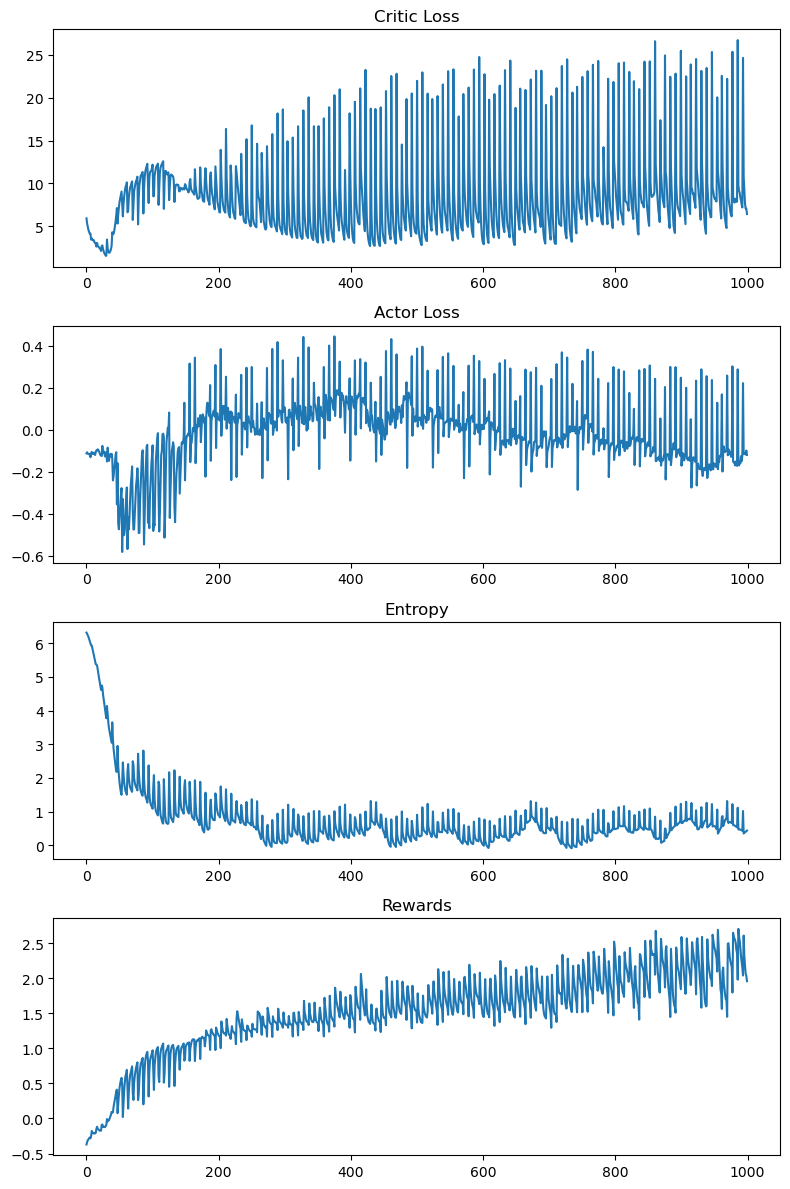

In [5]:
configuration = 'eisep_all'
info_path = f'./rl/result/halfcheetah/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
with open(info_path, 'rb') as f:
    info = pkl.load(f)
critic_loss = info['critic_loss']
actor_loss = info['actor_loss']
entropies = info['entropy']
rewards = info['rewards']
fig, ax = plt.subplots(4, 1, figsize=(8, 12))
ax[0].plot(np.mean(critic_loss, axis=0))
ax[0].set_title('Critic Loss')
ax[1].plot(np.mean(actor_loss, axis=0))
ax[1].set_title('Actor Loss')
ax[2].plot(np.mean(entropies, axis=0))
ax[2].set_title('Entropy')
ax[3].plot(np.mean(rewards, axis=0))
ax[3].set_title('Rewards')
plt.tight_layout()
plt.show()

In [ ]:

# n_showcase_episodes = 3
# device = 'cuda'

# # configuration = 'eisep_all'
# # create a new sample environment to get new random parameters
# # env = RecordVideo(gym.make(env_name, render_mode="rgb_array", max_episode_steps=500),
# #                         video_folder=f"./videos/{prefix}",
# #                         name_prefix=f"lunarlander")
# env = gym.make(env_name)
# obs_shape = env.observation_space.shape[0]
# action_shape = env.action_space.shape[0]
# print(f"obs shape: {obs_shape}, action shape: {action_shape}")
# weights_path = f"weights/halfcheetah/{configuration}_weight.pth"
# # info_path = f'./result/halfcheetah/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
# weight = torch.load(weights_path)

# reward_ar = np.zeros((n_showcase_episodes))

# device = 'cuda'
# seed = 0
# torch.manual_seed(seed)
# np.random.seed(seed)
# agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
# agent.load_state_dict(weight)
# agent.eval()
# agent.to(device)
# for episode in range(n_showcase_episodes):
#     print(f"starting episode {episode}...")
#     # get an initial state
#     state, info = env.reset()

#     # play one episode
#     done = False
#     hidden = agent.init_hidden(batch_size=1)
#     rewards = 0.
#     while not done:
#         # select an action A_{t} using S_{t} as input for the agent
#         with torch.no_grad():
#             action, _, _, _, new_hidden = agent.select_action(state[None, :], hidden)

#         # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
#         state, reward, terminated, truncated, info = env.step(action.detach().cpu().numpy()[0])
#         rewards += reward

#         # update if the environment is done
#         done = terminated or truncated
#         hidden = agent.reset_hidden_on_done(new_hidden, torch.tensor([done]))

#     print(f"Episode {episode} finished with return {rewards}")
#     env.close()

In [8]:
from torch import seed


def test(configuration, n_showcase_episodes, actor_lr, critic_lr, simple_type, ei_type):
    # env_name = "LunarLander-v3"
    env_name = "HalfCheetah-v5"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_seed = 5
    n_envs = 1
    randomize_domain = False
    hidden_size = 64

    env = gym.make(env_name)
    obs_shape = env.observation_space.shape[0]
    action_shape = env.action_space.shape[0]
    print(f"obs shape: {obs_shape}, action shape: {action_shape}")
    lrname=f'critic_{critic_lr}_actor_{actor_lr}'
    info_path = f'./rl/result/halfcheetah/simple_{simple_type}_ei_{ei_type}/{lrname}/{configuration}.pkl'
    with open(info_path, 'rb') as f:
        info = pkl.load(f)
    net_state_dicts = info['net_state_dict']
    reward_ar = np.zeros((n_seed, n_showcase_episodes))
    # info_path = f'./result/halfcheetah/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
    # weight = torch.load(weights_path)

    for seed in range(n_seed):
        env = gym.make(env_name)
        device = 'cuda'
        torch.manual_seed(seed)
        np.random.seed(seed)
        agent = ContinuousA2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration,
                              simple_type, ei_type)
        agent.load_state_dict(net_state_dicts[seed])
        agent.eval()
        agent.to(device)
        for episode in range(n_showcase_episodes):
            print(f"starting episode {episode}...")
            # get an initial state
            state, info = env.reset()

            # play one episode
            done = False
            # hidden = (torch.zeros((1, hidden_size), device=device), torch.zeros((1, hidden_size), device=device))
            hidden = agent.init_hidden(batch_size=1)
            rewards = 0.
            while not done:
                # select an action A_{t} using S_{t} as input for the agent
                with torch.no_grad():
                    action, _, _, _, new_hidden = agent.select_action(state[None, :], hidden)

                # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
                state, reward, terminated, truncated, info = env.step(action.detach().cpu().numpy()[0])
                rewards += reward

                # update if the environment is done
                done = terminated or truncated
                # h_critic, h_actor = new_hidden
                # h_critic = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_critic).to(device), h_critic)
                # h_actor = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_actor).to(device), h_actor)
                # hidden = (h_critic, h_actor)
                hidden = agent.reset_hidden_on_done(new_hidden, torch.tensor([done]))
            reward_ar[seed, episode] = rewards
        env.close()
    return reward_ar

In [ ]:
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
n_showcase_episodes = 20
n_seed = 5
reward_ars = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, n_showcase_episodes))

simple_type = 'lstm'
ei_type = 'eisep'
for a, actor_lr in enumerate(actor_lrs):
    for c, critic_lr in enumerate(critic_lrs):
        for i, configuration in enumerate(configurations):
            print(f"Testing configuration: {configuration}, actor_lr: {actor_lr}, critic_lr: {critic_lr}")
            reward_ars[a,c,i] = test(configuration, n_showcase_episodes, actor_lr, critic_lr, simple_type, ei_type)
np.save(f'./rl/result/halfcheetah/simple_{simple_type}_ei_{ei_type}/reward_ars.npy', reward_ars)

Testing configuration: simple, actor_lr: 0.0003, critic_lr: 0.0015
obs shape: 17, action shape: 6
Using <class 'net.rnncell_variant.SimpleLSTMCell'> RNN for actor and critic
starting episode 0...
starting episode 1...
starting episode 2...
starting episode 3...
starting episode 4...
starting episode 5...
starting episode 6...
starting episode 7...
starting episode 8...
starting episode 9...
starting episode 10...
starting episode 11...
starting episode 12...
starting episode 13...
starting episode 14...
starting episode 15...
starting episode 16...
starting episode 17...
starting episode 18...
starting episode 19...
Using <class 'net.rnncell_variant.SimpleLSTMCell'> RNN for actor and critic
starting episode 0...
starting episode 1...
starting episode 2...
starting episode 3...
starting episode 4...
starting episode 5...
starting episode 6...
starting episode 7...
starting episode 8...
starting episode 9...
starting episode 10...
starting episode 11...
starting episode 12...
starting ep

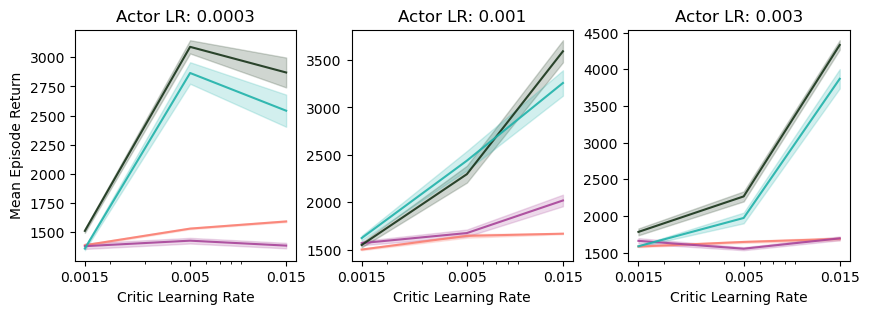

: 

In [ ]:
reward_ars = np.load(f'./rl/result/halfcheetah/simple_{simple_type}_ei_{ei_type}/reward_ars.npy')
reward_ar_flatten = reward_ars.reshape(len(actor_lrs), len(critic_lrs), len(configurations),  -1)
mean_r = np.mean(reward_ar_flatten, axis=-1)
ste_r = np.std(reward_ar_flatten, axis=-1)/np.sqrt(reward_ar_flatten.shape[-1])
fig, ax = plt.subplots(1,3,figsize=(10,3))
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
for i in range(len(actor_lrs)):
    for j in range(len(configurations)):
        ax[i].plot(critic_lrs, mean_r[i,:,j], label=config_names[j], alpha=0.9, color=colors[j])
        ax[i].fill_between(critic_lrs,
                          mean_r[i,:,j]-ste_r[i,:,j],
                          mean_r[i,:,j]+ste_r[i,:,j], alpha=0.2, color=colors[j])
    # ax[i].set_xticks(critic_lrs)
    ax[i].set_xlabel("Critic Learning Rate")

    ax[i].set_title(f"Actor LR: {actor_lrs[i]}")
    # ax[i].legend()
    ax[i].set_xscale('log')
    ax[i].set_xticks(critic_lrs, labels=critic_lrs)
ax[0].set_ylabel("Mean Episode Return")
plt.subplots_adjust(wspace=0.25)
plt.show()

In [ ]:
def score(weight, module):
    sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
    exc_ratio = -1
    if hasattr(module, 'get_ei_entropy_loss'):
        eimask_logit = module.eimask_logit.detach().cpu().numpy()
        exc_ratio = np.mean(eimask_logit[:,0]>eimask_logit[:,1])
    return sparsity, exc_ratio
def sparsity_analysis(configurations, critic_lr, actor_lr):
    # critic_lr = 0.005
    # actor_lr = 0.001
    hidden_size = 64
    env_name = "HalfCheetah-v5"
    colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
    config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_seed = 5
    n_envs = 1
    randomize_domain = False
    hidden_size = 64
    if randomize_domain:
        env = gym.make(
            "LunarLander-v3",
            gravity=np.clip(
                np.random.normal(loc=-10.0, scale=2.0), a_min=-11.99, a_max=-0.01
            ),
            enable_wind=np.random.choice([True, False]),
            wind_power=np.clip(
                np.random.normal(loc=15.0, scale=2.0), a_min=0.01, a_max=19.99
            ),
            turbulence_power=np.clip(
                np.random.normal(loc=1.5, scale=1.0), a_min=0.01, a_max=1.99
            ),
            max_episode_steps=500,
        )
    else:
        env = gym.make(env_name, max_episode_steps=500)
    obs_shape = env.observation_space.shape[0]
    action_shape = env.action_space.shape[0]
    sparsity_all = np.zeros((len(configurations), n_seed, 2))
    for i, configuration in enumerate(configurations):
        info_path = f'./result/halfcheetah/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
        with open(info_path, 'rb') as f:
            info = pkl.load(f)
        net_state_dicts = info['net_state_dict']

        # environment setup

        device = 'cuda'
        sparsity = np.zeros((n_seed, 2))
        for seed, state_dict in enumerate(net_state_dicts):
            agent = ContinuousA2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
            agent.load_state_dict(net_state_dicts[seed])
            agent.eval()
            agent.to(device)
            W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
            W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()
            sparsity_critic, exc_ratio_critic = score(W_critic, agent.critic)
            sparsity_actor, exc_ratio_actor = score(W_actor, agent.actor)
            sparsity_all[i, seed, 0] = sparsity_critic
            sparsity_all[i, seed, 1] = sparsity_actor
    return sparsity_all

In [ ]:
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
n_showcase_episodes = 20
n_seed = 5
sparsity_ars = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, 2))
for a, actor_lr in enumerate(actor_lrs):
    for c, critic_lr in enumerate(critic_lrs):
        print(f"actor_lr: {actor_lr}, critic_lr: {critic_lr}")
        sparsity_ars[a,c] = sparsity_analysis(configurations, critic_lr, actor_lr)


In [ ]:
sparsity_flatten = sparsity_ars.transpose(2,0,1,3,4).reshape(len(configurations), -1, 2)
fig, ax = plt.subplots(figsize=(5,3))
fontsize = 20
x = np.arange(len(configurations))
width = 0.35
critic_means = np.mean(sparsity_flatten[:,:,0], axis=1)
critic_stes = np.std(sparsity_flatten[:,:,0], axis=1)/np.sqrt(sparsity_flatten.shape[1])
actor_means = np.mean(sparsity_flatten[:,:,1], axis=1)
actor_stes = np.std(sparsity_flatten[:,:,1], axis=1)/np.sqrt(sparsity_flatten.shape[1])
ax.bar(x - width/2, critic_means, width, yerr=critic_stes, label='Critic', capsize=4, color='#2965FF')
ax.bar(x + width/2, actor_means, width, yerr=actor_stes, label='Actor', capsize=4, color='#C73D3D')
ax.set_xticks(x)
ax.set_xticklabels(config_names, fontsize=fontsize, rotation=15)
ax.set_title('Recurrent weight sparsity', fontsize=fontsize)
ax.tick_params(labelsize=fontsize-2)
ax.legend(fontsize=fontsize-4, frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
from cut import signed_spectral_W
def modularity_analysis(configurations):
    actor_lrs = [0.0003, 0.001, 0.003]
    critic_lrs = [0.0015, 0.005, 0.015]
    hidden_size = 64
    env_name = "HalfCheetah-v5"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_seed = 5
    n_envs = 1
    randomize_domain = False
    hidden_size = 64
    env = gym.make(env_name, max_episode_steps=500)
    obs_shape = env.observation_space.shape[0]
    action_shape = env.action_space.shape[0]
    print("Starting modularity analysis...", obs_shape, action_shape)
    # net_state_dicts: list of list of state_dict
    # model_names: list of model names
    # Returns: Q_all, Frustr_all, Ncut_all: [n_model, n_seed, n_k, 2]

    k_min = 2
    k_max = 10
    Q_all = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    Frustr_all = np.ones((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    Ncut_all = np.ones((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    # Q_all = np.zeros((len(configurations), n_seed, k_max - k_min + 1, 2))
    # Frustr_all = np.ones((len(configurations), n_seed, k_max - k_min + 1, 2))
    # Ncut_all = np.ones((len(configurations), n_seed, k_max - k_min + 1, 2))
    for a, actor_lr in enumerate(actor_lrs):
        for c, critic_lr in enumerate(critic_lrs):
            for i, configuration in enumerate(configurations):
                info_path = f'./result/halfcheetah/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
                with open(info_path, 'rb') as f:
                    info = pkl.load(f)
                net_state_dicts = info['net_state_dict']

                # environment setup

                device = 'cuda'
                for seed, state_dict in enumerate(net_state_dicts):
                    agent = ContinuousA2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
                    agent.load_state_dict(net_state_dicts[seed])
                    agent.eval()
                    agent.to(device)
                    W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()[-hidden_size:]
                    W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()[-hidden_size:]

                    df_critic, _ = signed_spectral_W(W_critic, k_min, k_max, restarts=5, seed=0)
                    Q_all[a,c,i,seed,:,0] = df_critic['Q'].values
                    Frustr_all[a,c,i,seed,:,0] = df_critic['Frustr'].values
                    Ncut_all[a,c,i,seed,:,0] = df_critic['Ncut'].values

                    df_actor, _ = signed_spectral_W(W_actor, k_min, k_max, restarts=5, seed=0)
                    Q_all[a,c,i,seed,:,1] = df_actor['Q'].values
                    Frustr_all[a,c,i,seed,:,1] = df_actor['Frustr'].values
                    Ncut_all[a,c,i,seed,:,1] = df_actor['Ncut'].values


    return Q_all, Frustr_all, Ncut_all

In [ ]:
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
Q_all, Frustr_all, Ncut_all = modularity_analysis(configurations)
pkl.dump({'Q_all': Q_all, 'Frustr_all': Frustr_all, 'Ncut_all': Ncut_all}, open('./result/halfcheetah/modularity_analysis.pkl', 'wb'))

In [ ]:
from turtle import color


metric_name = ['Q', 'Frustration', 'Ncut']
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
k_min = 2
k_max = 10
fig, ax = plt.subplots(2,3, figsize=(12,6))
fontsize = 18
ax = ax.flatten()
Q_flatten = Q_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
Frustr_flatten = Frustr_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
Ncut_flatten = Ncut_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
for i, metric in enumerate([Q_flatten, Frustr_flatten, Ncut_flatten]):
    mean_metric = np.mean(metric, axis=1)
    ste_metric = np.std(metric, axis=1)/np.sqrt(metric.shape[1])
    for j in range(mean_metric.shape[0]):
        ax[i].plot(np.arange(k_min, k_max+1), mean_metric[j,:,0], label=f'{configurations[j]} Critic', alpha=0.9,
                   marker='o', markeredgecolor='white', markeredgewidth=1, markersize=10, color=colors[j])
        ax[i].fill_between(np.arange(k_min, k_max+1), mean_metric[j,:,0] - ste_metric[j,:,0], mean_metric[j,:,0] + ste_metric[j,:,0],
                           alpha=0.1, color=colors[j])
        ax[i+len(metric_name)].plot(np.arange(k_min, k_max+1), mean_metric[j,:,1], label=f'{configurations[j]} Actor', alpha=0.9,
                   marker='o', markeredgecolor='white', markeredgewidth=1, markersize=10, color=colors[j])
        ax[i+len(metric_name)].fill_between(np.arange(k_min, k_max+1), mean_metric[j,:,1] - ste_metric[j,:,1], mean_metric[j,:,1] + ste_metric[j,:,1],
                                            alpha=0.1, color=colors[j])
    # ax[i].legend()
    ax[i+len(metric_name)].set_xlabel("Number of clusters k", fontsize=fontsize)
    ax[i].tick_params(labelsize=fontsize)
    ax[i+len(metric_name)].tick_params(labelsize=fontsize)
    ax[i].set_xticks(np.arange(k_min, k_max+1))
    ax[i+len(metric_name)].set_xticks(np.arange(k_min, k_max+1))
ax[0].set_title("Modularity Q (Higher is better)", fontsize=fontsize)
ax[1].set_title("Frustration (Lower is better)", fontsize=fontsize)
ax[2].set_title("Normalized Cut (Lower is better)", fontsize=fontsize)
ax[0].set_ylabel("Critic", fontsize=fontsize)
ax[3].set_ylabel("Actor", fontsize=fontsize)
plt.tight_layout()
plt.show()

---


## Training the A2C Agent

For our training loop, we are using the `RecordEpisodeStatistics` wrapper to record the episode lengths and returns and we are also saving
the losses and entropies to plot them after the agent finished training.

You may notice that we don't reset the vectorized envs at the start of each episode like we would usually do.
This is because each environment resets automatically once the episode finishes (each environment takes a different number of timesteps to finish
an episode because of the random seeds). As a result, we are also not collecting data in `episodes`, but rather just play a certain number of steps
(`n_steps_per_update`) in each environment (as an example, this could mean that we play 20 timesteps to finish an episode and then
use the rest of the timesteps to begin a new one).


In [ ]:

def train(configuration, n_updates, actor_lr, critic_lr):
    # environment hyperparams
    n_seed = 5
    n_envs = 10
    n_steps_per_update = 128
    randomize_domain = False

    # agent hyperparams
    gamma = 0.999
    lam = 0.95  # hyperparameter for GAE
    ent_coef = 0.01  # coefficient for the entropy bonus (to encourage exploration)

    hidden_size = 64

    # env_name = "LunarLander-v3"
    env_name = "HalfCheetah-v5"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic

    # environment setup
    envs = gym.make_vec(env_name, num_envs=n_envs)


    obs_shape = envs.single_observation_space.shape[0] # for LunarLander
    # obs_shape = envs.single_observation_space.n # for FrozenLake
    # action_shape = envs.single_action_space.n # For LunarLander
    action_shape = envs.single_action_space.shape[0]  # for HalfCheetah
    # print(f"obs shape: {obs_shape}, action shape: {action_shape}")
    # set the device
    use_cuda = True
    if use_cuda:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        device = torch.device("cpu")

    critic_losses = np.zeros((n_seed, n_updates))
    actor_losses = np.zeros((n_seed, n_updates))
    entropies = np.zeros((n_seed, n_updates))
    returns = np.zeros((n_seed, n_updates))
    net_state_dicts = [None] * n_seed
    for seed in range(n_seed):
        torch.manual_seed(seed)
        np.random.seed(seed)
        # init the agent
        agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
        # create a wrapper environment to save episode returns and episode lengths
        envs_wrapper = gym.wrappers.vector.RecordEpisodeStatistics(
            envs, buffer_length=n_envs * n_updates
        )

        agent.train()
        prefix = configuration
        # use tqdm to get a progress bar for training
        for sample_phase in tqdm(range(n_updates)):
            # we don't have to reset the envs, they just continue playing
            # until the episode is over and then reset automatically

            # reset lists that collect experiences of an episode (sample phase)
            ep_value_preds = torch.zeros(n_steps_per_update, n_envs, device=device)
            ep_rewards = torch.zeros(n_steps_per_update, n_envs, device=device)
            ep_action_log_probs = torch.zeros(n_steps_per_update, n_envs, device=device)
            masks = torch.zeros(n_steps_per_update, n_envs, device=device)

            # at the start of training reset all envs to get an initial state
            if sample_phase == 0:
                states, info = envs_wrapper.reset(seed=42)
                h_critic = torch.zeros((n_envs, hidden_size), device=device)
                h_actor = torch.zeros((n_envs, hidden_size), device=device)
                hidden = (h_critic, h_actor)

            # play n steps in our parallel environments to collect data
            h_critic, h_actor = hidden
            hidden = (h_critic.detach(), h_actor.detach())
            for step in range(n_steps_per_update):
                # select an action A_{t} using S_{t} as input for the agent
                actions, action_log_probs, state_value_preds, entropy, new_hidden = agent.select_action(
                    states, hidden
                )
                # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
                states, rewards, terminated, truncated, infos = envs_wrapper.step(
                    actions.cpu().numpy()
                )

                ep_value_preds[step] = torch.squeeze(state_value_preds)
                ep_rewards[step] = torch.tensor(rewards, device=device)
                ep_action_log_probs[step] = action_log_probs

                # add a mask (for the return calculation later);
                # for each env the mask is 1 if the episode is ongoing and 0 if it is terminated (not by truncation!)
                masks[step] = torch.tensor([not term for term in terminated])

                # reset hidden state for terminated environments
                h_critic, h_actor = new_hidden
                done = torch.BoolTensor(terminated).unsqueeze(1).to(device)
                h_critic = torch.where(done, torch.zeros_like(h_critic).to(device), h_critic)
                h_actor = torch.where(done, torch.zeros_like(h_actor).to(device), h_actor)
                hidden = (h_critic, h_actor)


            # calculate the losses for actor and critic
            critic_loss, actor_loss = agent.get_losses(
                ep_rewards,
                ep_action_log_probs,
                ep_value_preds,
                entropy,
                masks,
                gamma,
                lam,
                ent_coef,
                device,
            )
            # update the actor and critic networks
            agent.update_parameters(critic_loss, actor_loss)

            # log the losses and entropy
            # critic_losses.append(critic_loss.detach().cpu().numpy())
            # actor_losses.append(actor_loss.detach().cpu().numpy())
            # entropies.append(entropy.detach().mean().cpu().numpy())
            critic_losses[seed, sample_phase] = critic_loss.detach().cpu().numpy()
            actor_losses[seed, sample_phase] = actor_loss.detach().cpu().numpy()
            entropies[seed, sample_phase] = entropy.detach().mean().cpu().numpy()
            returns[seed, sample_phase] = ep_rewards.mean().cpu().numpy()
        net_state_dicts[seed] = agent.state_dict()
    info = {
        'critic_loss': critic_losses,
        'actor_loss': actor_losses,
        'entropy': entropies,
        'net_state_dict': net_state_dicts,
        'rewards': returns,
    }
    lrname=f'critic_{critic_lr}_actor_{actor_lr}'
    info_path = f'./result/halfcheetah/{lrname}/{prefix}.pkl'
    os.makedirs(os.path.dirname(info_path), exist_ok=True)
    with open(info_path, 'wb') as f:
        pkl.dump(info, f)
    return info


In [ ]:
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
# actor_lrs = [0.0003, 0.001, 0.003]
# critic_lrs = [0.0015, 0.005, 0.015]
actor_lrs = [0.003]
critic_lrs = [0.015]
for actor_lr in actor_lrs:
    for critic_lr in critic_lrs:
        for config in configurations:
            print(f"Training configuration: {config}, actor_lr: {actor_lr}, critic_lr: {critic_lr}")
            train(configuration=config, n_updates=1000, actor_lr=actor_lr, critic_lr=critic_lr)

<img src="file://_static/img/tutorials/vector_env_a2c_training_plots.png" alt="training_plots">


## Performance Analysis of Synchronous and Asynchronous Vectorized Environments


---

Asynchronous environments can lead to quicker training times and a higher speedup
for data collection compared to synchronous environments. This is because asynchronous environments
allow multiple agents to interact with their environments in parallel,
while synchronous environments run multiple environments serially.
This results in better efficiency and faster training times for asynchronous environments.


<img src="file://_static/img/tutorials/vector_env_performance_plots.png" alt="performance_plots">


---

According to the Karp-Flatt metric (a metric used in parallel computing to estimate the limit for the
speedup when scaling up the number of parallel processes, here the number of environments),
the estimated max. speedup for asynchronous environments is 57, while the estimated maximum speedup
for synchronous environments is 21. This suggests that asynchronous environments have significantly
faster training times compared to synchronous environments (see graphs).


<img src="file://_static/img/tutorials/vector_env_karp_flatt_plot.png" alt="karp_flatt_metric">


---

However, it is important to note that increasing the number of parallel vector environments
can lead to slower training times after a certain number of environments (see plot below, where the
agent was trained until the mean training returns were above -120). The slower training times might occur
because the gradients of the environments are good enough after a relatively low number of environments
(especially if the environment is not very complex). In this case, increasing the number of environments
does not increase the learning speed, and actually increases the runtime, possibly due to the additional time
needed to calculate the gradients. For LunarLander-v3, the best performing configuration used a AsyncVectorEnv
with 10 parallel environments, but environments with a higher complexity may require more
parallel environments to achieve optimal performance.


<img src="file://_static/img/tutorials/vector_env_runtime_until_threshold.png" alt="runtime_until_threshold_plot">


## References

[1] V. Mnih, A. P. Badia, M. Mirza, A. Graves, T. P. Lillicrap, T. Harley, D. Silver, K. Kavukcuoglu. "Asynchronous Methods for Deep Reinforcement Learning" ICML (2016).

[2] J. Schulman, P. Moritz, S. Levine, M. Jordan and P. Abbeel. "High-dimensional continuous control using generalized advantage estimation." ICLR (2016).

[3] Gymnasium Documentation: Vector environments. (URL: https://gymnasium.farama.org/api/vector/)


In [ ]:
def test(configuration, n_showcase_episodes, actor_lr, critic_lr):
    # env_name = "LunarLander-v3"
    env_name = "MountainCar-v0"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_seed = 5
    n_envs = 1
    randomize_domain = False
    hidden_size = 64
    # environment setup
    if randomize_domain:
        env = gym.make(
            "LunarLander-v3",
            gravity=np.clip(
                np.random.normal(loc=-10.0, scale=2.0), a_min=-11.99, a_max=-0.01
            ),
            enable_wind=np.random.choice([True, False]),
            wind_power=np.clip(
                np.random.normal(loc=15.0, scale=2.0), a_min=0.01, a_max=19.99
            ),
            turbulence_power=np.clip(
                np.random.normal(loc=1.5, scale=1.0), a_min=0.01, a_max=1.99
            ),
            max_episode_steps=500,
        )
    else:
        env = gym.make(env_name, max_episode_steps=500)

    obs_shape = env.observation_space.shape[0]
    action_shape = env.action_space.n
    # actor_weights_path = f"weights/{configuration}/actor_weights.h5"
    # critic_weights_path = f"weights/{configuration}/critic_weights.h5"
    info_path = f'./result/mountaincar/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
    with open(info_path, 'rb') as f:
        info = pkl.load(f)
    net_state_dicts = info['net_state_dict']
    reward_ar = np.zeros((n_seed, n_showcase_episodes))
    for seed in range(n_seed):
        device = 'cuda'
        torch.manual_seed(seed)
        np.random.seed(seed)
        agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
        agent.load_state_dict(net_state_dicts[seed])
        agent.eval()
        agent.to(device)

        for episode in range(n_showcase_episodes):
            # print(f"starting episode {episode}...")
            # get an initial state
            state, info = env.reset()
            # play one episode
            done = False
            hidden = (torch.zeros((1, hidden_size), device=device), torch.zeros((1, hidden_size), device=device))
            rewards = 0.
            while not done:
                # select an action A_{t} using S_{t} as input for the agent
                with torch.no_grad():
                    action, _, _, _, new_hidden = agent.select_action(state[None, :], hidden)
                # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
                state, reward, terminated, truncated, info = env.step(action.item())
                rewards += reward

                # update if the environment is done
                done = terminated or truncated
                h_critic, h_actor = new_hidden
                h_critic = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_critic).to(device), h_critic)
                h_actor = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_actor).to(device), h_actor)
                hidden = (h_critic, h_actor)
            reward_ar[seed, episode] = rewards
            env.close()
    return reward_ar

In [ ]:
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
n_showcase_episodes = 20
n_seed = 5
reward_ars = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, n_showcase_episodes))
for a, actor_lr in enumerate(actor_lrs):
    for c, critic_lr in enumerate(critic_lrs):
        for i, configuration in enumerate(configurations):
            print(f"Testing configuration: {configuration}, actor_lr: {actor_lr}, critic_lr: {critic_lr}")
            reward_ars[a,c,i] = test(configuration, n_showcase_episodes, actor_lr, critic_lr)
np.save('./result/mountaincar/reward_ars.npy', reward_ars)

In [ ]:
reward_ars = np.load('./result/lunarlander/reward_ars.npy')
reward_ar_flatten = reward_ars.reshape(len(actor_lrs), len(critic_lrs), len(configurations),  -1)
mean_r = np.mean(reward_ar_flatten, axis=-1)
ste_r = np.std(reward_ar_flatten, axis=-1)/np.sqrt(reward_ar_flatten.shape[-1])
fig, ax = plt.subplots(1,3,figsize=(10,3))
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
for i in range(len(actor_lrs)):
    for j in range(len(configurations)):
        ax[i].plot(critic_lrs, mean_r[i,:,j], label=config_names[j], alpha=0.9, color=colors[j])
        ax[i].fill_between(critic_lrs,
                          mean_r[i,:,j]-ste_r[i,:,j],
                          mean_r[i,:,j]+ste_r[i,:,j], alpha=0.2, color=colors[j])
    # ax[i].set_xticks(critic_lrs)
    ax[i].set_xlabel("Critic Learning Rate")

    ax[i].set_title(f"Actor LR: {actor_lrs[i]}")
    # ax[i].legend()
    ax[i].set_xscale('log')
    ax[i].set_xticks(critic_lrs, labels=critic_lrs)
ax[0].set_ylabel("Mean Episode Return")
plt.subplots_adjust(wspace=0.25)
plt.show()

In [ ]:


def plot_recurrent_weight(agent):
    W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
    W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()
    sparsity_critic, exc_ratio_critic = score(W_critic, agent.critic)
    sparsity_actor, exc_ratio_actor = score(W_actor, agent.actor)
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8, 3))
    axs[0].set_title(f"Critic, sparsity={sparsity_critic:.2f}, exc_ratio={exc_ratio_critic:.2f}")
    limit = np.max(np.abs(W_critic))
    im0 = axs[0].imshow(W_critic, vmin=-limit, vmax=limit, cmap='bwr')
    plt.colorbar(im0, ax=axs[0])
    axs[1].set_title(f"Actor, sparsity={sparsity_actor:.2f}, exc_ratio={exc_ratio_actor:.2f}")
    limit = np.max(np.abs(W_actor))
    im1 = axs[1].imshow(W_actor, vmin=-limit, vmax=limit, cmap='bwr')
    plt.colorbar(im1, ax=axs[1])
    plt.suptitle("Recurrent weight matrices after training")
    plt.tight_layout()
    plt.show()
# plot_recurrent_weight(agent)

def plot_loss_curve(configurations):
    fig, ax = plt.subplots(1,4, figsize=(15,3))
    for configuration in configurations:
        info_path = f'./result/lunarlander/critic005actor001/{configuration}.pkl'
        with open(info_path, 'rb') as f:
            info = pkl.load(f)
        critic_loss = info['critic_loss']
        actor_loss = info['actor_loss']
        entropy = info['entropy']
        reward = info['reward_queue']
        print('critic loss:', critic_loss.shape, 'actor_loss:', actor_loss.shape, 'entropy:', entropy.shape, 'reward:', len(reward))
        for r in reward:
            print('  reward length:', len(r), 'mean reward:', np.mean(r))
        ax[0].set_title("Critic Loss")
        mean_critic_loss = np.mean(critic_loss, axis=0)
        ste_critic_loss = np.std(critic_loss, axis=0)/np.sqrt(critic_loss.shape[0])
        ax[0].plot(mean_critic_loss, label=configuration, alpha=0.8)
        ax[0].fill_between(np.arange(len(mean_critic_loss)), mean_critic_loss - ste_critic_loss, mean_critic_loss + ste_critic_loss, alpha=0.2)
        ax[1].set_title("Actor Loss")
        mean_actor_loss = np.mean(actor_loss, axis=0)/np.sqrt(actor_loss.shape[0])
        ste_actor_loss = np.std(actor_loss, axis=0)/np.sqrt(actor_loss.shape[0])
        ax[1].plot(mean_actor_loss, label=configuration, alpha=0.8)
        ax[1].fill_between(np.arange(len(mean_actor_loss)), mean_actor_loss - ste_actor_loss, mean_actor_loss + ste_actor_loss, alpha=0.2)
        ax[2].set_title("Entropy")
        mean_entropy = np.mean(entropy, axis=0)
        ste_entropy = np.std(entropy, axis=0)/np.sqrt(entropy.shape[0])
        ax[2].plot(mean_entropy, label=configuration, alpha=0.8)
        ax[2].fill_between(np.arange(len(mean_entropy)), mean_entropy - ste_entropy, mean_entropy + ste_entropy, alpha=0.2)
        ax[3].set_title("Episode Return")
        reward_to_show = np.array([np.array(r)[-2500:] for r in reward])
        mean_reward = np.mean(reward_to_show, axis=0)
        reward_convolve = np.convolve(mean_reward, np.ones(20)/20, mode='same')
        mean_reward = reward_convolve
        ste_reward = np.std(reward_to_show, axis=0)/np.sqrt(reward_to_show.shape[0])
        ax[3].plot(mean_reward, label=configuration, alpha=0.8)
        ax[3].fill_between(np.arange(len(mean_reward)), mean_reward - ste_reward, mean_reward + ste_reward, alpha=0.2)
        for a in ax:
            a.set_xlabel("Training Updates")
            a.legend()
            # a.set_yscale('log')
    plt.tight_layout()
    plt.show()
    # for a in ax[:3]:
    #     a.set_xlabel("Training Updates")
    #     a.set_yscale('log')
# plot_loss_curve('simple')

In [ ]:
plot_loss_curve(configurations)

In [ ]:
def score(weight, module):
    sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
    exc_ratio = -1
    if hasattr(module, 'get_ei_entropy_loss'):
        eimask_logit = module.eimask_logit.detach().cpu().numpy()
        exc_ratio = np.mean(eimask_logit[:,0]>eimask_logit[:,1])
    return sparsity, exc_ratio
def sparsity_analysis(configurations, critic_lr, actor_lr):
    # critic_lr = 0.005
    # actor_lr = 0.001
    hidden_size = 64
    env_name = "LunarLander-v3"
    colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
    config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_seed = 5
    n_envs = 1
    randomize_domain = False
    hidden_size = 64
    if randomize_domain:
        env = gym.make(
            "LunarLander-v3",
            gravity=np.clip(
                np.random.normal(loc=-10.0, scale=2.0), a_min=-11.99, a_max=-0.01
            ),
            enable_wind=np.random.choice([True, False]),
            wind_power=np.clip(
                np.random.normal(loc=15.0, scale=2.0), a_min=0.01, a_max=19.99
            ),
            turbulence_power=np.clip(
                np.random.normal(loc=1.5, scale=1.0), a_min=0.01, a_max=1.99
            ),
            max_episode_steps=500,
        )
    else:
        env = gym.make(env_name, max_episode_steps=500)
    obs_shape = env.observation_space.shape[0]
    action_shape = env.action_space.n
    sparsity_all = np.zeros((len(configurations), n_seed, 2))
    for i, configuration in enumerate(configurations):
        info_path = f'./result/lunarlander/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
        with open(info_path, 'rb') as f:
            info = pkl.load(f)
        net_state_dicts = info['net_state_dict']

        # environment setup

        device = 'cuda'
        sparsity = np.zeros((n_seed, 2))
        for seed, state_dict in enumerate(net_state_dicts):
            agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
            agent.load_state_dict(net_state_dicts[seed])
            agent.eval()
            agent.to(device)
            W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
            W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()
            sparsity_critic, exc_ratio_critic = score(W_critic, agent.critic)
            sparsity_actor, exc_ratio_actor = score(W_actor, agent.actor)
            sparsity_all[i, seed, 0] = sparsity_critic
            sparsity_all[i, seed, 1] = sparsity_actor
    return sparsity_all


In [ ]:
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
n_showcase_episodes = 20
n_seed = 5
sparsity_ars = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, 2))
for a, actor_lr in enumerate(actor_lrs):
    for c, critic_lr in enumerate(critic_lrs):
        print(f"actor_lr: {actor_lr}, critic_lr: {critic_lr}")
        sparsity_ars[a,c] = sparsity_analysis(configurations, critic_lr, actor_lr)


In [ ]:
sparsity_flatten = sparsity_ars.transpose(2,0,1,3,4).reshape(len(configurations), -1, 2)
fig, ax = plt.subplots(figsize=(5,3))
fontsize = 20
x = np.arange(len(configurations))
width = 0.35
critic_means = np.mean(sparsity_flatten[:,:,0], axis=1)
critic_stes = np.std(sparsity_flatten[:,:,0], axis=1)/np.sqrt(sparsity_flatten.shape[1])
actor_means = np.mean(sparsity_flatten[:,:,1], axis=1)
actor_stes = np.std(sparsity_flatten[:,:,1], axis=1)/np.sqrt(sparsity_flatten.shape[1])
ax.bar(x - width/2, critic_means, width, yerr=critic_stes, label='Critic', capsize=4, color='#2965FF')
ax.bar(x + width/2, actor_means, width, yerr=actor_stes, label='Actor', capsize=4, color='#C73D3D')
ax.set_xticks(x)
ax.set_xticklabels(config_names, fontsize=fontsize, rotation=15)
ax.set_title('Recurrent weight sparsity', fontsize=fontsize)
ax.tick_params(labelsize=fontsize-2)
ax.legend(fontsize=fontsize-4, frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
# for a, actor_lr in enumerate(actor_lrs):
#     for c, critic_lr in enumerate(critic_lrs):
#         print(f"actor_lr: {actor_lr}, critic_lr: {critic_lr}")
#         sparsity_flatten = sparsity_ars[a,c]
#         fig, ax = plt.subplots(figsize=(5,3))
#         fontsize = 20
#         x = np.arange(len(configurations))
#         width = 0.35
#         critic_means = np.mean(sparsity_flatten[:,:,0], axis=1)
#         critic_stes = np.std(sparsity_flatten[:,:,0], axis=1)/np.sqrt(sparsity_flatten.shape[1])
#         actor_means = np.mean(sparsity_flatten[:,:,1], axis=1)
#         actor_stes = np.std(sparsity_flatten[:,:,1], axis=1)/np.sqrt(sparsity_flatten.shape[1])
#         ax.bar(x - width/2, critic_means, width, yerr=critic_stes, label='Critic', capsize=4, color='#2965FF')
#         ax.bar(x + width/2, actor_means, width, yerr=actor_stes, label='Actor', capsize=4, color='#C73D3D')
#         ax.set_xticks(x)
#         ax.set_xticklabels(config_names, fontsize=fontsize, rotation=15)
#         ax.set_title('Recurrent weight sparsity', fontsize=fontsize)
#         ax.tick_params(labelsize=fontsize-2)
#         ax.legend(fontsize=fontsize-4, frameon=False)
#         plt.tight_layout()
#         plt.show()
#         plt.close()

In [ ]:
from cut import signed_spectral_W
def modularity_analysis(configurations):
    critic_lr = 0.005
    actor_lr = 0.001
    hidden_size = 64
    env_name = "LunarLander-v3"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_seed = 5
    n_envs = 1
    randomize_domain = False
    hidden_size = 64
    if randomize_domain:
        env = gym.make(
            "LunarLander-v3",
            gravity=np.clip(
                np.random.normal(loc=-10.0, scale=2.0), a_min=-11.99, a_max=-0.01
            ),
            enable_wind=np.random.choice([True, False]),
            wind_power=np.clip(
                np.random.normal(loc=15.0, scale=2.0), a_min=0.01, a_max=19.99
            ),
            turbulence_power=np.clip(
                np.random.normal(loc=1.5, scale=1.0), a_min=0.01, a_max=1.99
            ),
            max_episode_steps=500,
        )
    else:
        env = gym.make(env_name, max_episode_steps=500)
    obs_shape = env.observation_space.shape[0]
    action_shape = env.action_space.n
    print("Starting modularity analysis...", obs_shape, action_shape)
    # net_state_dicts: list of list of state_dict
    # model_names: list of model names
    # Returns: Q_all, Frustr_all, Ncut_all: [n_model, n_seed, n_k, 2]

    k_min = 2
    k_max = 10
    Q_all = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    Frustr_all = np.ones((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    Ncut_all = np.ones((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    # Q_all = np.zeros((len(configurations), n_seed, k_max - k_min + 1, 2))
    # Frustr_all = np.ones((len(configurations), n_seed, k_max - k_min + 1, 2))
    # Ncut_all = np.ones((len(configurations), n_seed, k_max - k_min + 1, 2))
    for a, actor_lr in enumerate(actor_lrs):
        for c, critic_lr in enumerate(critic_lrs):
            for i, configuration in enumerate(configurations):
                info_path = f'./result/lunarlander/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
                with open(info_path, 'rb') as f:
                    info = pkl.load(f)
                net_state_dicts = info['net_state_dict']

                # environment setup

                device = 'cuda'
                for seed, state_dict in enumerate(net_state_dicts):
                    agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
                    agent.load_state_dict(net_state_dicts[seed])
                    agent.eval()
                    agent.to(device)
                    W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
                    W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()

                    df_critic, _ = signed_spectral_W(W_critic, k_min, k_max, restarts=5, seed=0)
                    Q_all[a,c,i,seed,:,0] = df_critic['Q'].values
                    Frustr_all[a,c,i,seed,:,0] = df_critic['Frustr'].values
                    Ncut_all[a,c,i,seed,:,0] = df_critic['Ncut'].values

                    df_actor, _ = signed_spectral_W(W_actor, k_min, k_max, restarts=5, seed=0)
                    Q_all[a,c,i,seed,:,1] = df_actor['Q'].values
                    Frustr_all[a,c,i,seed,:,1] = df_actor['Frustr'].values
                    Ncut_all[a,c,i,seed,:,1] = df_actor['Ncut'].values


    return Q_all, Frustr_all, Ncut_all

In [ ]:
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
Q_all, Frustr_all, Ncut_all = modularity_analysis(configurations)
pkl.dump({'Q_all': Q_all, 'Frustr_all': Frustr_all, 'Ncut_all': Ncut_all}, open('./result/lunarlander/modularity_analysis.pkl', 'wb'))

In [ ]:
from turtle import color


metric_name = ['Q', 'Frustration', 'Ncut']
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
k_min = 2
k_max = 10
fig, ax = plt.subplots(2,3, figsize=(12,6))
fontsize = 18
ax = ax.flatten()
Q_flatten = Q_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
Frustr_flatten = Frustr_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
Ncut_flatten = Ncut_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
for i, metric in enumerate([Q_flatten, Frustr_flatten, Ncut_flatten]):
    mean_metric = np.mean(metric, axis=1)
    ste_metric = np.std(metric, axis=1)/np.sqrt(metric.shape[1])
    for j in range(mean_metric.shape[0]):
        ax[i].plot(np.arange(k_min, k_max+1), mean_metric[j,:,0], label=f'{configurations[j]} Critic', alpha=0.9,
                   marker='o', markeredgecolor='white', markeredgewidth=1, markersize=10, color=colors[j])
        ax[i].fill_between(np.arange(k_min, k_max+1), mean_metric[j,:,0] - ste_metric[j,:,0], mean_metric[j,:,0] + ste_metric[j,:,0],
                           alpha=0.1, color=colors[j])
        ax[i+len(metric_name)].plot(np.arange(k_min, k_max+1), mean_metric[j,:,1], label=f'{configurations[j]} Actor', alpha=0.9,
                   marker='o', markeredgecolor='white', markeredgewidth=1, markersize=10, color=colors[j])
        ax[i+len(metric_name)].fill_between(np.arange(k_min, k_max+1), mean_metric[j,:,1] - ste_metric[j,:,1], mean_metric[j,:,1] + ste_metric[j,:,1],
                                            alpha=0.1, color=colors[j])
    # ax[i].legend()
    ax[i+len(metric_name)].set_xlabel("Number of clusters k", fontsize=fontsize)
    ax[i].tick_params(labelsize=fontsize)
    ax[i+len(metric_name)].tick_params(labelsize=fontsize)
    ax[i].set_xticks(np.arange(k_min, k_max+1))
    ax[i+len(metric_name)].set_xticks(np.arange(k_min, k_max+1))
ax[0].set_title("Modularity Q (Higher is better)", fontsize=fontsize)
ax[1].set_title("Frustration (Lower is better)", fontsize=fontsize)
ax[2].set_title("Normalized Cut (Lower is better)", fontsize=fontsize)
ax[0].set_ylabel("Critic", fontsize=fontsize)
ax[3].set_ylabel("Actor", fontsize=fontsize)
plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(6,4))
config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
for i in range(len(configurations)):
    ax.plot(0,0, label=f'{config_names[i]}', color=colors[i], alpha=1, linewidth=10)
ax.legend(fontsize=fontsize, loc='center', framealpha=1, shadow=True, markerscale=1)
ax.axis('off')
plt.show()